# Causal Forest semi-synthetic benchmark

This notebook:
1. cleans and subsamples LBIDD covariates
2. generates semi-synthetic potential outcomes and treatment assignments
3. fits `econml.dml.CausalForestDML`
4. computes raw and normalised PEHE
5. evaluates built-in importance and SHAP using Attrpred/Attrprog
6. confounding-strength sensitivity analysis.

The configuration values are collected in one place so the implementation can be matched directly to the report.

In [ ]:
#importing libraries
from dataclasses import dataclass
from pathlib import Path
from typing import Literal, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from econml.dml import CausalForestDML
import shap

import warnings
warnings.filterwarnings("ignore")

### 1. Load and clean LBIDD 

In [ ]:
def load_and_clean_lbidd(n_subsample: int = 3000, random_state: int = 42,
                          drop_near_constant_threshold: float = 0.99):

    path = Path("x.csv")
    if not path.exists():
        raise FileNotFoundError(f"Covariate file not found: {path}")
    
    data = pd.read_csv(path)
    if "sample_id" in data.columns:
        data = data.drop(columns=["sample_id"])

    keep_cols = []
    for col in data.columns:
        top_freq = data[col].value_counts(normalize=True, dropna=False).iloc[0]
        if top_freq < drop_near_constant_threshold:
            keep_cols.append(col)
    data = data[keep_cols]

    numeric_df = data.select_dtypes(include=[np.number])
    corr = numeric_df.corr().abs()
    to_drop = set()
    cols = list(corr.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            if c1 in to_drop or c2 in to_drop:
                continue
            if corr.loc[c1, c2] > 0.9:
                to_drop.add(c2)
    data = data.drop(columns=list(to_drop))
    data = data.select_dtypes(include=[np.number])

    if len(data) > n_subsample:
        data = data.sample(n=n_subsample, random_state=random_state).reset_index(drop=True)

    print(f"Cleaning summary: dropped {len(to_drop)} redundant columns; final shape: {data.shape}")
    return data

'''
Steps taken to clean file:
    - removed `sample_id` when present
    - retained numeric columns only
    - removed columns whose most frequent value occurs in at least 99% of rows
    - removed the later column from highly correlated pairs
    - take one reproducible random subsample.

'''

### 2. Data generating Process

In [ ]:
@dataclass
class DGPConfig:
    n_relevant_per_group: int = 5
    pred_scale: float = 1.0
    confound_type: Literal["none", "prognostic", "predictive"] = "none"
    confound_strength: float = 0.0
    noise_sd: float = 1.0
    random_seed: Optional[int] = None
 
 
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
 
 
def zscore(x):
    return (x - x.mean()) / (x.std() + 1e-8)
 
 
def generate_semi_synthetic_dataset(covariates: pd.DataFrame, config: DGPConfig):
# generating one semi-synthetic causal dataset and its feature ground truth
    rng = np.random.default_rng(config.random_seed)
    X = covariates.reset_index(drop=True)
    n, d = X.shape
    Xvals = X.values
 
    n_needed = 3 * config.n_relevant_per_group
    if d < n_needed:
        raise ValueError(f"Need at least {n_needed} covariates, got {d}.")
 
    all_idx = rng.choice(d, size=n_needed, replace=False)
    Iprog = all_idx[: config.n_relevant_per_group]
    I0 = all_idx[config.n_relevant_per_group: 2 * config.n_relevant_per_group]
    I1 = all_idx[2 * config.n_relevant_per_group:]
 
    prog_weights = rng.uniform(-1, 1, size=len(Iprog))
    pred0_weights = rng.uniform(-1, 1, size=len(I0))
    pred1_weights = rng.uniform(-1, 1, size=len(I1))
 
    def prog_fn(Xr): return Xr[:, Iprog] @ prog_weights
    def pred0_fn(Xr): return Xr[:, I0] @ pred0_weights
    def pred1_fn(Xr): return Xr[:, I1] @ pred1_weights
 
    prog_term = prog_fn(Xvals)
    Y0 = prog_term + config.pred_scale * pred0_fn(Xvals)
    Y1 = prog_term + config.pred_scale * pred1_fn(Xvals)
    true_ITE = Y1 - Y0
 
    if config.confound_strength == 0 or config.confound_type == "none":
        remaining = np.setdiff1d(np.arange(d), all_idx)
        irrelevant_idx = rng.choice(remaining, size=1)[0] if len(remaining) > 0 else None
        gamma = zscore(Xvals[:, irrelevant_idx]) if irrelevant_idx is not None else np.zeros(n)
    elif config.confound_type == "prognostic":
        gamma = zscore(prog_term)
    elif config.confound_type == "predictive":
        gamma = zscore(pred1_fn(Xvals) - pred0_fn(Xvals))
    else:
        raise ValueError(f"Unknown confound_type: {config.confound_type}")
 
    propensity = sigmoid(config.confound_strength * gamma)
    W = rng.binomial(1, propensity)
    noise = rng.normal(0, config.noise_sd, size=n)
    Y = W * Y1 + (1 - W) * Y0 + noise
 
    df = X.copy()
    df["W"], df["Y"], df["Y0"], df["Y1"], df["true_ITE"] = W, Y, Y0, Y1, true_ITE
 
    ground_truth = {
        "Iprog": list(X.columns[Iprog]),
        "I0": list(X.columns[I0]),
        "I1": list(X.columns[I1]),
        "Ipred": list(X.columns[I0]) + list(X.columns[I1]),
    }
    return df, ground_truth

### 3. Fit Causal Forest, extract explanations, compute PEHE

In [ ]:
def evaluate_causal_forest(df, test_size=0.2, random_state=42, compute_shap=True):

   #  Fit CausalForestDML and return importance values and PEHE metrics
    feature_cols = [c for c in df.columns if c not in ["W", "Y", "Y0", "Y1", "true_ITE"]]
    train_df, test_df = train_test_split(df, test_size=test_size, random_state=random_state)
 
    X_train, W_train, Y_train = train_df[feature_cols].values, train_df["W"].values, train_df["Y"].values
    X_test = test_df[feature_cols].values
    true_ite_test = test_df["true_ITE"].values
 
    model = CausalForestDML(n_estimators=200, random_state=random_state, discrete_treatment=True)
    model.fit(Y_train, W_train, X=X_train)
 
    predicted_ite = model.effect(X_test)
    pehe = float(np.sqrt(np.mean((predicted_ite - true_ite_test) ** 2)))
 
    true_ite_sd = float(np.std(true_ite_test)) + 1e-8
    pehe_normalised = pehe / true_ite_sd          # [NEW]
 
    cf_feature_importance = pd.Series(model.feature_importances_, index=feature_cols)

    #SHAP 
    if compute_shap:
        rng = np.random.default_rng(random_state)
        idx = rng.choice(len(X_test), 100, replace = False)
        background = X_test[idx]
        explainer = shap.Explainer(model.effect, background)
        shap_values = explainer(background)
        shap_importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_cols)
    

    else:
        shap_importance=None

    return cf_feature_importance, shap_importance, pehe, pehe_normalised

'''
#  pehe_normalised added: raw PEHE divided
# by the standard deviation of the true ITE in the test set. Raw PEHE is
# not comparable across pred_scale settings because the true effect's
# own magnitude grows with pred_scale. Dividing by the true ITE's spread
# puts PEHE on a comparable, relative scale across all conditions.
 
'''

In [ ]:
# Attrpred / Attrprog  

def compute_attr_metrics(importance, ground_truth):
    total = importance.abs().sum()
    if total == 0:
        return 0.0, 0.0
    attrpred = importance.reindex(ground_truth["Ipred"]).abs().sum() / total
    attrprog = importance.reindex(ground_truth["Iprog"]).abs().sum() / total
    return float(attrpred), float(attrprog)

### 4. Main experimental grid

In [ ]:
def run_full_grid(covariates, seeds, pred_scales, confound_configs, verbose=True):
    rows = []
    total_runs = len(seeds) * len(pred_scales) * len(confound_configs)
    run_count = 0
 
    for pred_scale in pred_scales:
        for confound_type, confound_strength in confound_configs:
            for seed in seeds:
                run_count += 1
                if verbose:
                    print(f"[{run_count}/{total_runs}] pred_scale={pred_scale}, "
                          f"confound={confound_type}({confound_strength}), seed={seed}")
 
                config = DGPConfig(pred_scale=pred_scale, confound_type=confound_type,
                                    confound_strength=confound_strength, random_seed=seed)
                df, ground_truth = generate_semi_synthetic_dataset(covariates, config)
 
                cf_imp, shap_imp, pehe, pehe_norm = evaluate_causal_forest(df, random_state=seed)
                bi_pred, bi_prog = compute_attr_metrics(cf_imp, ground_truth)
                shap_pred, shap_prog = compute_attr_metrics(shap_imp, ground_truth)
 
                rows.append({
                    "pred_scale": pred_scale, "confound_type": confound_type,
                    "confound_strength": confound_strength, "seed": seed,
                    "cf_attrpred": bi_pred, "cf_attrprog": bi_prog,
                    "shap_attrpred": shap_pred, "shap_attrprog": shap_prog,
                    "pehe": pehe, "pehe_normalised": pehe_norm,
                })

                #checkpoints
                if run_count % 50 == 0:
                    pd.DataFrame(rows).to_csv(
                        "causal_forest_results_checkpoint.csv",
                        index=False
                    )
                    print(f"Checkpoint saved ({run_count}/{total_runs})")
 
    return pd.DataFrame(rows)

#  pehe_normalised captured and stored alongside raw pehe.

### 5. Figure

In [ ]:
METRICS = ["cf_attrpred", "cf_attrprog", "shap_attrpred",
           "shap_attrprog", "pehe", "pehe_normalised"]
 
 
def summarise_with_dispersion(results_df, group_cols):
    g = results_df.groupby(group_cols)[METRICS]
    summary = g.mean().add_suffix("_mean").join(
        g.std().add_suffix("_std")).join(
        g.min().add_suffix("_min")).join(
        g.max().add_suffix("_max"))
    return summary
 
 
def make_all_figures(results_df):
    summary_mean = results_df.groupby(["pred_scale", "confound_type"])[METRICS].mean()
    summary_std = results_df.groupby(["pred_scale", "confound_type"])[METRICS].std()
    summary = summarise_with_dispersion(results_df, ["pred_scale", "confound_type"])
 
    # Figure 1: Attrpred by signal strength for built-in importance and SHAP.
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    for ax, method in zip(axes, ["cf", "shap"]):
        for confound_type in summary_mean.index.get_level_values("confound_type").unique():
            sm = summary_mean.xs(confound_type, level="confound_type")
            ss = summary_std.xs(confound_type, level="confound_type")
            ax.errorbar(sm.index, sm[f"{method}_attrpred"], yerr=ss[f"{method}_attrpred"],
                        marker="o", capsize=4, label=confound_type)
        ax.set_xlabel("Predictive signal strength")
        ax.set_title("Built-in Importance" if method == "cf" else "SHAP")
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Attrpred (mean \u00b1 1 SD)")
    axes[1].legend(title="Confounding mechanism")
    fig.suptitle("Explanation fidelity across predictive signal strengths")
    plt.tight_layout()
    plt.savefig("cf_figure1_attrpred_vs_signal.png", dpi=150)
    plt.show()
 
    # Figure 2: Built-in importance vs SHAP/.
    fig, ax = plt.subplots(figsize=(10, 5))
    conditions = [f"{ps}\n{ct}" for ps, ct in summary_mean.index]
    x = np.arange(len(conditions))
    width = 0.35
    ax.bar(x - width/2, summary_mean["cf_attrpred"], width,
           yerr=summary_std["cf_attrpred"], capsize=3, label="Causal Forest importance")
    ax.bar(x + width/2, summary_mean["shap_attrpred"], width,
           yerr=summary_std["shap_attrpred"], capsize=3, label="SHAP")
    ax.set_xticks(x)
    ax.set_xticklabels(conditions, fontsize=8)
    ax.set_ylabel("Mean Attrpred \u00b1 1 SD")
    ax.set_title("Comparison of Explanation Methods Across Experimental Conditions")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig("cf_figure2_builtin_vs_shap.png", dpi=150)
    plt.show()
 
    # Figure 3: Normalised PEHE by signal strength
    fig, ax = plt.subplots(figsize=(7, 5))
    for confound_type in summary_mean.index.get_level_values("confound_type").unique():
        sm = summary_mean.xs(confound_type, level="confound_type")
        ss = summary_std.xs(confound_type, level="confound_type")
        ax.errorbar(sm.index, sm["pehe_normalised"], yerr=ss["pehe_normalised"],
                    marker="o", capsize=4, label=confound_type)
    ax.set_xlabel("Predictive signal strength")
    ax.set_ylabel("Normalised PEHE")
    ax.set_title("Normalised PEHE across predictive signal strengths")
    ax.legend(title="Confounding mechanism")
    ax.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig("cf_figure3_pehe_normalised.png", dpi=150)
    plt.show()


  
# Figure 4: Estimation accuracy vs explanation fidelity

    fig, ax = plt.subplots(figsize=(8, 6))

    colours = {
        "none": "tab:green",
        "prognostic": "tab:blue",
        "predictive": "tab:red"
    }

    markers = {
        "cf": "o",
        "SHAP": "^"
    }

    # Mean over seeds for cleaner visualisation
    scatter_summary = results_df.groupby(
        ["pred_scale", "confound_type"]
    ).agg({
        "pehe_normalised": "mean",
        "cf_attrpred": "mean",
        "shap_attrpred": "mean"
    }).reset_index()

    for method, col in [("cf", "cf_attrpred"),
                        ("SHAP", "shap_attrpred")]:

        for conf in scatter_summary["confound_type"].unique():

            d = scatter_summary[scatter_summary["confound_type"] == conf]

            ax.scatter(
                d["pehe_normalised"],
                d[col],
                s=90,
                marker=markers[method],
                color=colours[conf],
                label=f"{method} - {conf}"
            )

            # annotate predictive signal strength
            for _, row in d.iterrows():
                ax.annotate(
                    f"{row['pred_scale']}",
                    (row["pehe_normalised"], row[col]),
                    fontsize=8,
                    xytext=(4, 4),
                    textcoords="offset points"
                )

    ax.set_xlabel("Mean normalised PEHE")
    ax.set_ylabel("Mean Attrpred")
    ax.set_title("Estimation Accuracy and explanation fidelity")

    ax.grid(True, linestyle="--", alpha=0.4)

    # remove duplicate legend entries
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), fontsize=8)

    plt.tight_layout()
    plt.savefig("Figure4_PEHE_vs_Attrpred.png", dpi=300)
    plt.show()
 
    return summary

In [ ]:
#  Run everything
 
if __name__ == "__main__":
    print("Loading data...")
    covariates = load_and_clean_lbidd(f"x.csv", n_subsample=3000)
    print("Covariate shape:", covariates.shape)
 
    if covariates.shape[1] < 15:
        raise ValueError(f"Only {covariates.shape[1]} variables available. Need at least 15 covariates.")
 
    # [CHANGED] seeds raised to 30, per supervisor feedback
    seeds = range(1, 31)
    pred_scales = [0.05, 0.3, 1.0]
    confound_configs = [("none", 0.0), ("prognostic", 5.0), ("predictive", 5.0)]
 
    print("Running main experimental grid (30 seeds)...")
    results = run_full_grid(covariates, seeds, pred_scales, confound_configs)
 
    print("\nResults shape:", results.shape)
    if results.empty:
        raise ValueError("Results are empty. The causal forest runs failed.")
 
    results.to_csv("causal_forest_results.csv", index=False)
 
    print("\n--- Summary (mean, std, min, max across seeds) ---")
    summary = make_all_figures(results)
    print(summary)
    summary.to_csv("causal_forest_summary.csv")
 
    print("\nFinished successfully!")
 

### 6.  Confounding-strength sensitivity experiment

In [ ]:
def run_confounding_strength_sweep(covariates, seeds, pred_scale, confound_strengths):
    rows = []
    total_runs = len(seeds) * len(confound_strengths) * 2  # prognostic + predictive
    run_count = 0
    for confound_type in ["prognostic", "predictive"]:
        for strength in confound_strengths:
            for seed in seeds:
                run_count += 1
                print(f"[{run_count}/{total_runs}] strength={strength}, type={confound_type}, seed={seed}")
                config = DGPConfig(pred_scale=pred_scale, confound_type=confound_type,
                                    confound_strength=strength, random_seed=seed)
                df, ground_truth = generate_semi_synthetic_dataset(covariates, config)
                cf_imp, _, pehe, pehe_norm = evaluate_causal_forest(df, random_state=seed, compute_shap=False)
                bi_pred, bi_prog = compute_attr_metrics(cf_imp, ground_truth)
                rows.append({
                    "confound_type": confound_type, "confound_strength": strength, "seed": seed,
                    "cf_attrpred": bi_pred, 
                    "pehe_normalised": pehe_norm,
                })
    return pd.DataFrame(rows)

In [ ]:
covariates = load_and_clean_lbidd(
    "x.csv",
    n_subsample=3000
)

# Confounding-strength sensitivity experiemnt at strong signal (pred_scale=1.0)
print("\nRunning confounding-strength sensitivity sweep...")
strength_sweep = run_confounding_strength_sweep(
    covariates, seeds=range(1, 16),   # 15 seeds is enough for this secondary sweep
    pred_scale=1.0,
    confound_strengths=[1.0, 3.0, 5.0, 8.0, 10.0]
    )
strength_sweep.to_csv("confounding_strength_sweep.csv", index=False)
 
strength_summary = strength_sweep.groupby(["confound_type", "confound_strength"])[
    ["cf_attrpred", "pehe_normalised"]
].agg(["mean", "std"])
print("\n--- Confounding-strength sweep summary ---")
print(strength_summary)
strength_summary.to_csv("confounding_strength_summary.csv")

print("\nSensitivity analysis finished!")

Cleaning summary: dropped 58 redundant columns; final shape: (3000, 74)

Running confounding-strength sensitivity sweep...
[1/150] strength=1.0, type=prognostic, seed=1
[2/150] strength=1.0, type=prognostic, seed=2
[3/150] strength=1.0, type=prognostic, seed=3
[4/150] strength=1.0, type=prognostic, seed=4
[5/150] strength=1.0, type=prognostic, seed=5
[6/150] strength=1.0, type=prognostic, seed=6
[7/150] strength=1.0, type=prognostic, seed=7
[8/150] strength=1.0, type=prognostic, seed=8
[9/150] strength=1.0, type=prognostic, seed=9
[10/150] strength=1.0, type=prognostic, seed=10
[11/150] strength=1.0, type=prognostic, seed=11
[12/150] strength=1.0, type=prognostic, seed=12
[13/150] strength=1.0, type=prognostic, seed=13
[14/150] strength=1.0, type=prognostic, seed=14
[15/150] strength=1.0, type=prognostic, seed=15
[16/150] strength=3.0, type=prognostic, seed=1
[17/150] strength=3.0, type=prognostic, seed=2
[18/150] strength=3.0, type=prognostic, seed=3
[19/150] strength=3.0, type=progno

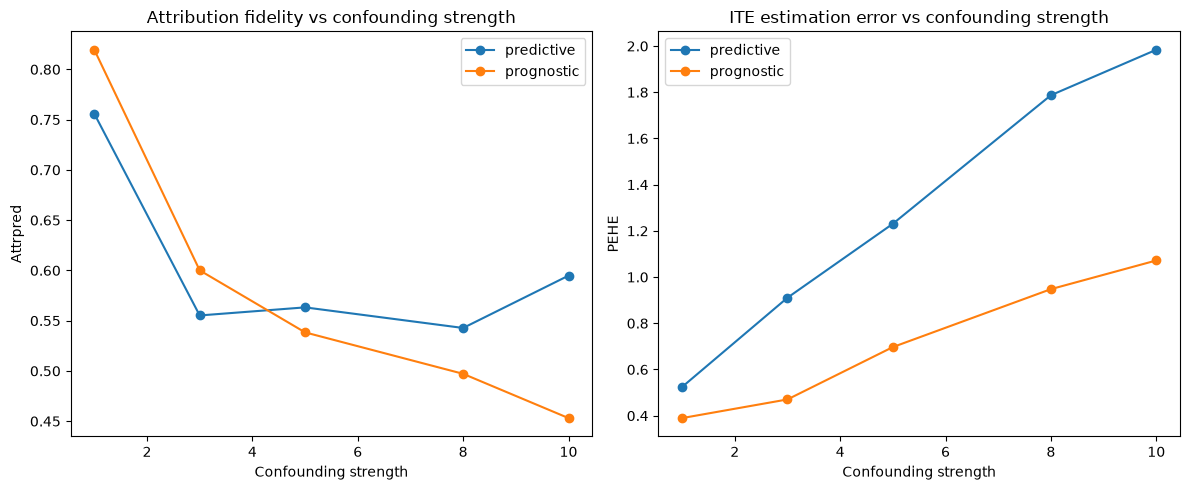

In [11]:
# Sensitivity plot

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


plot_data = strength_sweep.groupby(
    ["confound_type", "confound_strength"]
)[
    ["cf_attrpred", "pehe_normalised"]
].mean().reset_index()


for confound_type in plot_data["confound_type"].unique():

    data = plot_data[
        plot_data["confound_type"] == confound_type
    ]

    axes[0].plot(
        data["confound_strength"],
        data["cf_attrpred"],
        marker="o",
        label=confound_type
    )


    axes[1].plot(
        data["confound_strength"],
        data["pehe_normalised"],
        marker="o",
        label=confound_type
    )


axes[0].set_xlabel("Confounding strength")
axes[0].set_ylabel("Attrpred")
axes[0].set_title("Attribution fidelity vs confounding strength")


axes[1].set_xlabel("Confounding strength")
axes[1].set_ylabel("PEHE")
axes[1].set_title("ITE estimation error vs confounding strength")


axes[0].legend()
axes[1].legend()

plt.tight_layout()

plt.savefig(
    "confounding_strength_sensitivity.png",
    dpi=300
)
plt.savefig("Figure5.png")
plt.show()

In [2]:
cf_summary = pd.read_csv("causal_forest_summary_updated.csv").copy()


In [3]:
cf_summary.columns

Index(['pred_scale', 'confound_type', 'cf_attrpred_mean', 'cf_attrprog_mean',
       'shap_attrpred_mean', 'shap_attrprog_mean', 'pehe_mean',
       'pehe_normalised_mean', 'cf_attrpred_std', 'cf_attrprog_std',
       'shap_attrpred_std', 'shap_attrprog_std', 'pehe_std',
       'pehe_normalised_std', 'cf_attrpred_min', 'cf_attrprog_min',
       'shap_attrpred_min', 'shap_attrprog_min', 'pehe_min',
       'pehe_normalised_min', 'cf_attrpred_max', 'cf_attrprog_max',
       'shap_attrpred_max', 'shap_attrprog_max', 'pehe_max',
       'pehe_normalised_max'],
      dtype='str')

In [4]:
cf_summary.drop(columns = ["pehe_std","cf_attrpred_max", "cf_attrpred_min", "shap_attrpred_min", "shap_attrpred_max", "cf_attrprog_max", "cf_attrprog_min", "shap_attrprog_min", "shap_attrprog_max" , "pehe_max", "pehe_normalised_max", "pehe_min", "pehe_normalised_min", "pehe_mean"], inplace=True)

In [5]:
cf_summary.to_csv("cf_summary.csv")

In [7]:
confounding_strength_sum = pd.read_csv("confounding_strength_summary_updated.csv").copy()

In [ ]:
confounding_strength_sum.column

Index(['Unnamed: 0', 'Unnamed: 1', 'cf_attrpred', 'cf_attrpred.1',
       'pehe_normalised', 'pehe_normalised.1'],
      dtype='str')

In [11]:
confounding_strength_sum.columns = ["confound_type", "confound_strength", "cf_attrpred_mean", "cf_attrpred_std", "pehe_normalised", "pehe_normalised_std"]

In [14]:
confounding_strength_sum.to_csv(
    "confounding_strength_summ.csv",
    index=False,
    float_format="%.4f"
)